# Ejercicio 5

## Contexto

Los datos se encuentran en el fichero **centro_fp_monitorizacion.csv**

Algunos docentes han comunicado sensación de aire cargado y cansancio en determinadas clases. La dirección sospecha que la concentración de CO₂ podría ser demasiado alta cuando las aulas están ocupadas, pero no sabe si ocurre en todas por igual ni en qué franjas.

Se considera que una lectura de **CO₂ superior a 1.000ppm** requiere atención, y que superar **1.200ppm** es especialmente preocupante. Estos valores son umbrales de trabajo de este caso simulado, no un diagnóstico sanitario.

## Lo que tienes que hacer

1. ¿Existen diferencias relevantes de calidad del aire entre las tres aulas? Identifica cuál priorizarías.
2. ¿Los problemas están distribuidos a lo largo del día o se concentran en determinados horarios?
3. ¿Qué relación observas entre la ocupación del aula y el nivel de CO₂? ¿La relación basta para explicar todas las lecturas altas?
4. ¿Hay problemas de calidad de datos que puedan alterar las conclusiones? Explica cómo los has tratado.
5. ¿Qué acciones concretas recomendarías a la dirección y cómo verificarías que funcionan?

## Entrega

- actividad.py o .ipynb
- alertas_aire.json
- Gráficas que consideres necesarias en formato jpg
- Informe de conclusiones > actividad.md o actividad.ipynb

In [ ]:
import pandas

# Lo primero sería extraer los datos del csv
datos = pandas.read_csv("centro_fp_monitorizacion.csv")
#print(datos)

# Lo segundo, limpiar los datos de duplicados, nulos, etc.
print(f"Total de registros del csv: {len(datos)}")
# duplicated() y isna() --> drop_duplicates() dropna()
print(f"Duplicados: {datos.duplicated().sum()}")
print(f"Nulos: {datos.isna().sum()}")
datos_depurados = datos.drop_duplicates().dropna()
print(f"Total de registros para tratar: {len(datos_depurados)}")
print(f"Registros eliminados: {len(datos)-len(datos_depurados)}")


Total de registros del csv: 363
Duplicados: 3
Nulos: fecha                0
dia                  0
hora                 0
aula                 0
alumnos              0
temperatura_c        0
humedad_pct          0
co2_ppm              6
consumo_kwh          0
dispositivos_wifi    0
desconexiones        0
latencia_ms          0
dtype: int64
Total de registros para tratar: 354
Registros eliminados: 9


In [18]:
# Datos de CO2 por aula
# Aula A
datos_aula_a = datos_depurados[datos_depurados["aula"] == 'A']
datos_co2_aula_a = datos_aula_a["co2_ppm"]
print(f"Media de co2 en el aula A: {round(datos_co2_aula_a.mean(),2)}")

# Incidencias | >1000 alta y >1200 crítica
# Aula A
print(f"Incidencias en aula a: {datos_aula_a[(datos_aula_a["co2_ppm"] > 1000) | (datos_aula_a["co2_ppm"] > 1200)]}")
print(f"Total incidencias aula a: {len(datos_aula_a[(datos_aula_a["co2_ppm"] > 1000) | (datos_aula_a["co2_ppm"] > 1200)])}")

Media de co2 en el aula A: 737.62
Incidencias en aula a:           fecha  dia  hora aula  alumnos  temperatura_c  humedad_pct  co2_ppm  \
109  2026-10-04    4     9    A       28           21.4         50.8   1101.0   
116  2026-10-04    4    16    A       26           24.3         49.7   1015.0   
182  2026-10-06    6    10    A       29           20.6         54.0   1023.0   
220  2026-10-07    7    12    A       24           20.4         41.1   1002.0   
252  2026-10-08    8     8    A       27           20.8         58.2   1017.0   
258  2026-10-08    8    14    A       26           22.6         48.5   1038.0   
296  2026-10-09    9    16    A       29           21.5         59.0   1017.0   
328  2026-10-10   10    12    A       28           23.1         54.8   1055.0   

     consumo_kwh  dispositivos_wifi  desconexiones  latencia_ms  
109         4.08                 32              2         79.8  
116         3.84                 33              0         65.3  
182         4.2

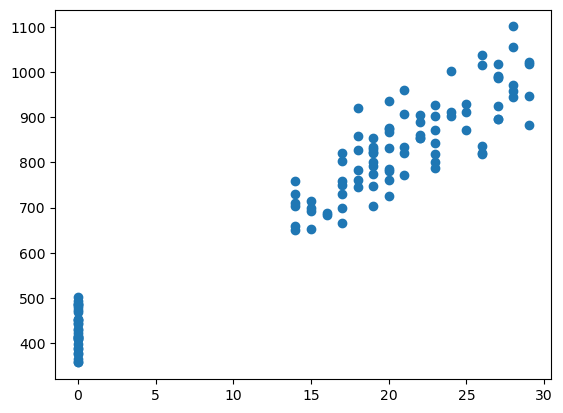

In [ ]:
import matplotlib.pyplot as plt

#plt.plot(datos_aula_a["dia"],datos_aula_a["co2_ppm"])
plt.scatter(datos_aula_a["alumnos"],datos_aula_a["co2_ppm"])
plt.show()


Con el gráfico de dispersión entre número de alumnos y co2 en clase ya sabemos que hay una relación para que se produzca una incidencia (>1000), necesariamente debe haber más de 25 alumnos en clase para que suceda, pero no es una relación lineal, no tiene por qué suceder porque hay otras causas que lo producen (ej.: mala ventilación).